In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, MultipleLocator

## Perception maps

In [2]:
# sin percertion map
def Phi_s(y, n):
    return np.clip(
        y - np.sin((y - .5) * np.pi * n * 2) / (n * np.pi * 2),
        0, 1)

# cubic perception map
def Phi_c(y, a):
    y = 2*y - 1
    return .5 * (a*y + (1-a)*y**3 + 1)


# bounded confidence kernel
def theta(x, y, r):
    d = np.abs(x - y)
    return (d <= r).astype(float)

## Agent based model

In [3]:
def simulate_a(
    N=100,
    steps=100000,
    gamma=0.5,
    Phi=lambda x: x,
    x0=None,
    r=0.2
):
    # initial opinions
    if x0 is None:
        x = np.random.uniform(0, 1, N)
    else:
        x = np.array(x0, dtype=float)

    history = np.empty((steps + 1, N))
    history[0] = x.copy()
    interaction_history = []
    
    for t in range(steps):
        i, j = np.random.choice(N, size=2, replace=True)
        xi = x[i] 
        xj = x[j]
        new_xi = xi
        new_xj = xj
        if np.abs(xi-Phi(xj)) < r:
            new_xi = (1-gamma)*xi + gamma*Phi(xj)
            events_t.append(t)
            events_x.append(new_xi)
            events_i.append(i)
            
        if np.abs(xj-Phi(xi)) < r:
            new_xj = (1-gamma)*xj + gamma*Phi(xi)
            events_t.append(t)
            events_x.append(new_xj)
            events_i.append(j)
            
        x[i] = new_xi
        x[j] = new_xj
        
        history[t + 1] = x

    return x, history


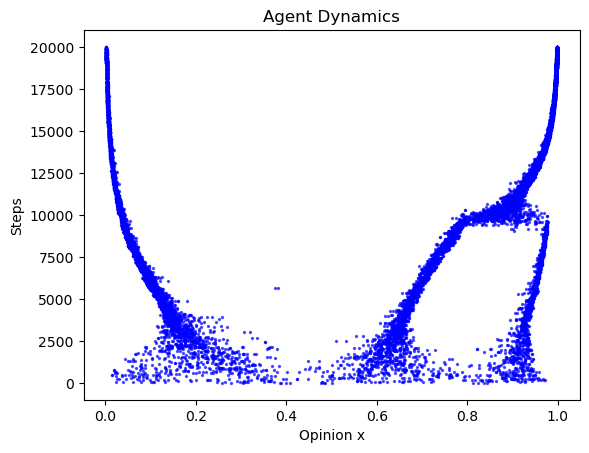

In [4]:
a=1.1
Phi = lambda x: Phi_c(x,a)

steps=20000

events_t = []
events_x = []
events_i = []
x_final, history = simulate_a(
    N=200,
    steps=steps,
    gamma=.4,
    Phi=Phi,
    r=0.17
    )

plt.scatter(
    events_x,
    events_t,
    s=2,
    color='blue',
    alpha=0.6,
    )
plt.xlabel("Opinion x")
plt.ylabel("Steps")
plt.title('Agent Dynamics')
plt.show()

## Density based model

In [5]:
# ---Helper functions---

#interpolation on the grid
def build_interp(phij):
    Xp = xgrid[:, None] - gamma * (
        xgrid[:, None] - phij[None, :]
    )

    Xp = np.clip(Xp, xgrid[0], xgrid[-1])

    kf = (Xp - xgrid[0]) / dx
    k = np.clip(np.floor(kf).astype(int), 0, N-2)
    t = kf - k

    return k.ravel(), t.ravel()

#normalizing the kernel
def build_theta(phij, r):
    norm = np.trapezoid(
        theta(mid, xgrid, r),
        xgrid
    )

    return (
        theta(
            xgrid[:, None],
            phij[None, :],
            r
        ) / norm
    ).ravel()

#right hand side of governing equation
def make_rhs(Theta, k, t):
    kp1 = k + 1
    w_lo = 1 - t
    w_hi = t

    def rhs(f):
        raw = (
            Theta
            * np.repeat(f, N)
            * np.tile(f, N)
        )

        loss = raw.reshape(N, N).sum(axis=1)

        gain = (
            np.bincount(
                k,
                raw * w_lo,
                minlength=N
            )
            +
            np.bincount(
                kp1,
                raw * w_hi,
                minlength=N
            )
        )

        return 2 * dx * (gain - loss)

    return rhs

#Runge-Kutta step
def rk4(f, rhs, dt):
    k1 = rhs(f)
    k2 = rhs(f + .5 * dt * k1)
    k3 = rhs(f + .5 * dt * k2)
    k4 = rhs(f + dt * k3)

    fnew = f + dt * (
        k1 + 2*k2 + 2*k3 + k4
    ) / 6

    fnew = np.maximum(fnew, 0)

    mass = np.trapezoid(fnew, xgrid)

    if mass <= 1e-12 or not np.isfinite(mass):
        return f.copy()

    return fnew / mass



# ---Solver---

# Solver for perception map parameter a, confidence bound r
def simulate_d(f, a, r, steps, check_every=10, tolerance=1e-5):

    phij = Phi(xgrid, a)
    k, t = build_interp(phij)
    Theta = build_theta(phij, r)
    rhs = make_rhs(Theta, k, t)

    for n in range(steps):
        f = rk4(f, rhs, dt)
    return f



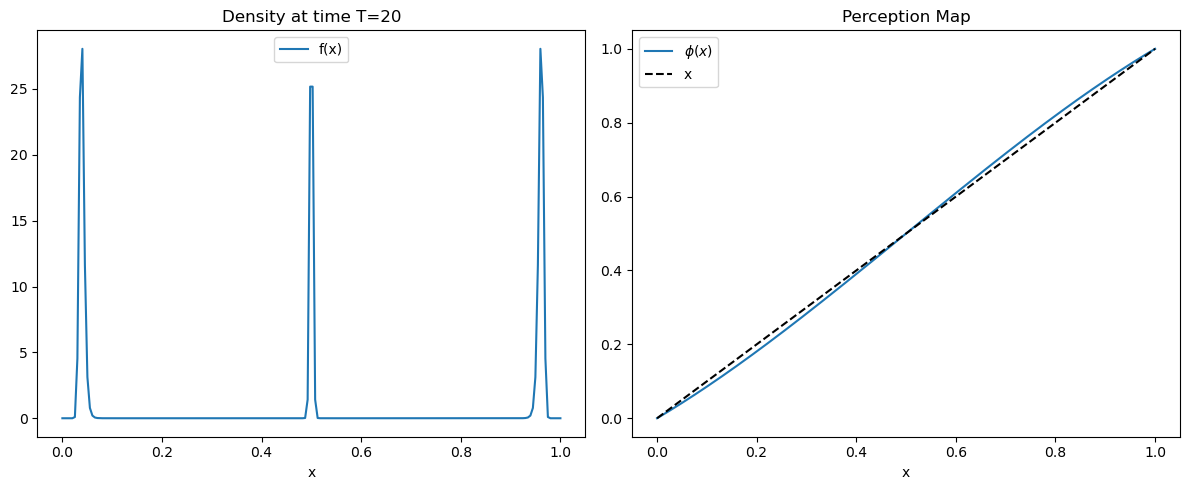

In [6]:
#Parameters
N = 200
xgrid = np.linspace(0, 1, N)
dx = xgrid[1] - xgrid[0]
mid = xgrid[N//2]

gamma = .4
Phi = Phi_c

T = 20
dt = .05
steps = int(T / dt)

f0 = np.ones_like(xgrid)
f0 /= np.trapezoid(f0, xgrid)

#run solver
a = 1.1
r = 0.2
f = simulate_d(f0, a, r, steps)



fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Density plot
ax1.plot(xgrid, f, label='f(x)')
ax1.set_title('Density at time T=' + str(T))
ax1.set_xlabel("x")
ax1.legend()

# Perception map plot
ax2.plot(xgrid, Phi(xgrid, a), label=r'$\phi(x)$')
ax2.plot(xgrid, xgrid, '--', label='x', c='black')
ax2.set_title('Perception Map')
ax2.set_xlabel("x")
ax2.legend()

plt.tight_layout() 
plt.show()


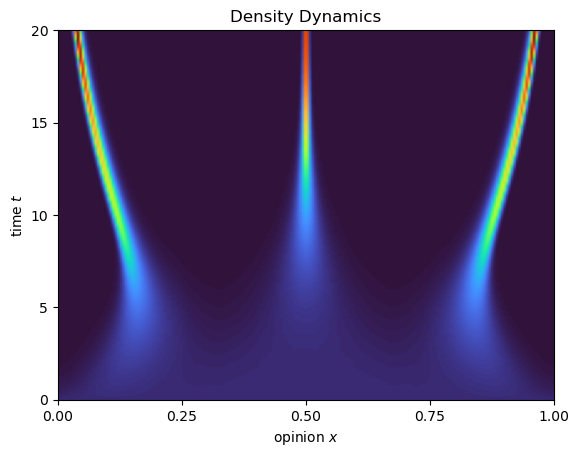

In [8]:
#Density dynamics

snapshots = [f0.copy()]
for n in range(steps):
    f = simulate_d(snapshots [-1],a,r, 1)
    snapshots.append(f.copy())
data  = np.array(snapshots)
tgrid = np.arange(data.shape[0]) * dt

fig, ax = plt.subplots()
pcm = ax.pcolormesh(xgrid, tgrid, data, cmap='turbo',
                    shading='gouraud', rasterized=True,
                    vmin=0)  
ax.set_xlabel(r'opinion $x$')
ax.set_ylabel(r'time $t$')
ax.xaxis.set_major_locator(FixedLocator([0, 0.25, 0.5, 0.75, 1]))
ax.yaxis.set_major_locator(MultipleLocator(5))
ax.set_title('Density Dynamics')
plt.show()